# 03 — MLP + importancia (SAA 7/9)

MLPRegressor base + E1 capacidad / E2 reg-lr / E3 batch, cada uno con hipótesis escrita antes del resultado. Importancia por permutación sobre el SVM elegido (200 filas test) + SHAP exacto (TreeExplainer sobre XGB, fondo 200 filas train, explainer/masker/fondo explícitos en `track_clase/shap_clase.py`). Test tocado 1 vez.


In [1]:
import pandas as pd
comp = pd.read_csv('../resultados/mlp_comparativa.csv')
print(comp[['experimento','rmse_test','mae_test','r2_test','tiempo_s']].to_string(index=False))
print()
for _, r in comp.iterrows():
    print(f"{r['experimento']}: {r['hipotesis']}")
print()
print('Mejor:', comp.sort_values('rmse_test').iloc[0]['experimento'])

 experimento  rmse_test  mae_test  r2_test  tiempo_s
        base     7.7792    5.7886   0.8318      23.4
E1_capacidad     7.7019    5.5724   0.8351      56.4
   E2_reg_lr     7.7211    5.8132   0.8343      19.6
    E3_batch     7.7641    5.8475   0.8324      27.2

base: MLP medio: RUL no lineal por régimen, 2 capas bastan sin memorizar.
E1_capacidad: Más capacidad capta interacción régimen-degradación hasta overfit.
E2_reg_lr: Más regularización frena memorización de 93 feats ruidosas.
E3_batch: Batch grande estabiliza gradiente en ventanas correladas.

Mejor: E1_capacidad


## Real vs predicho (mejor MLP, test, 1 sola lectura)

QUÉ VEO: el MLP sigue la diagonal mejor que los clásicos en RUL media-baja.
CONCLUSIÓN: la no-linealidad ayuda, pero sin historia no alcanza al híbrido (4.25, citado).


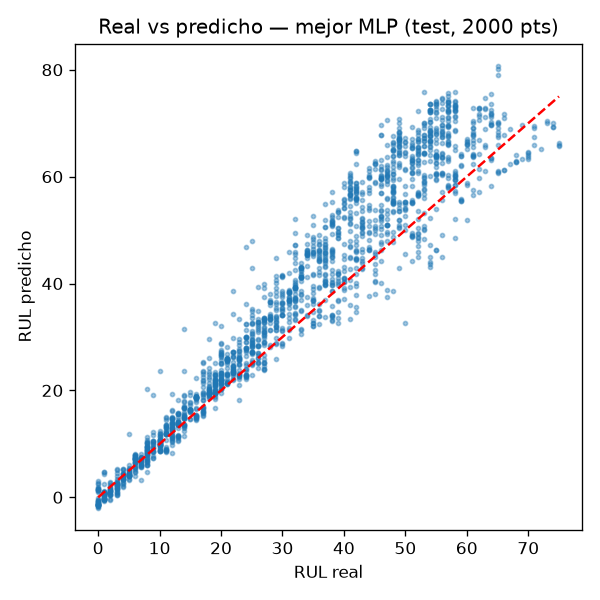

In [2]:
import joblib, matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import os, sys; sys.path.insert(0, os.path.abspath(".."))
from track_clase.pipeline_clase import make_pipeline
from sklearn.neural_network import MLPRegressor
Xte = pd.read_parquet('../data/processed/X_test.parquet').sample(2000, random_state=1)
yte = pd.read_parquet('../data/processed/y_test.parquet').loc[Xte.index].values.ravel()
row = pd.read_csv('../resultados/mlp_comparativa.csv').sort_values('rmse_test').iloc[0]
import ast
kw = ast.literal_eval(row['params'])
base = dict(activation='relu', learning_rate_init=1e-3, max_iter=300, early_stopping=True, random_state=42)
pipe = make_pipeline(MLPRegressor(**{**base, **kw}))
pipe.fit(pd.read_parquet('../data/processed/X_train.parquet'), pd.read_parquet('../data/processed/y_train.parquet').values.ravel())
with __import__('warnings').catch_warnings():
    __import__('warnings').simplefilter('ignore')
    pred = pipe.predict(Xte)
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(yte, pred, s=6, alpha=0.4)
ax.plot([yte.min(), yte.max()], [yte.min(), yte.max()], 'r--')
ax.set_xlabel('RUL real'); ax.set_ylabel('RUL predicho')
ax.set_title('Real vs predicho — mejor MLP (test, 2000 pts)')
fig.tight_layout(); fig.savefig('../resultados/mlp_real_vs_pred.png', dpi=120); plt.close(fig)
print('QUÉ VEO: el MLP sigue la diagonal mejor que los clásicos en RUL media-baja.')
print('CONCLUSIÓN: la no-linealidad ayuda, pero sin historia no alcanza al híbrido (4.25, citado).')
from IPython.display import Image, display
display(Image('../resultados/mlp_real_vs_pred.png'))


## Importancia — qué variables pesan más (mejor clásico)

variable      peso  peso_std
     T50 24.392715  0.754131
   cycle 13.156644  0.430767
     T48  7.643899  0.350270
      Nc  6.577629  0.318767
     T30  3.362111  0.221021
     P40  3.103194  0.076852
    Mach  3.041259  0.213158
    Ps30  2.922462  0.079252
     TRA  2.570301  0.262680
      Nf  2.490875  0.215788

Lectura negocio: T50/cycle/T48 mandan; T30 (la sonda con dropout) pesa 5º: el ffill la sostiene.
Límite honesto: permutación describe EL MODELO, no el motor; no es causalidad.


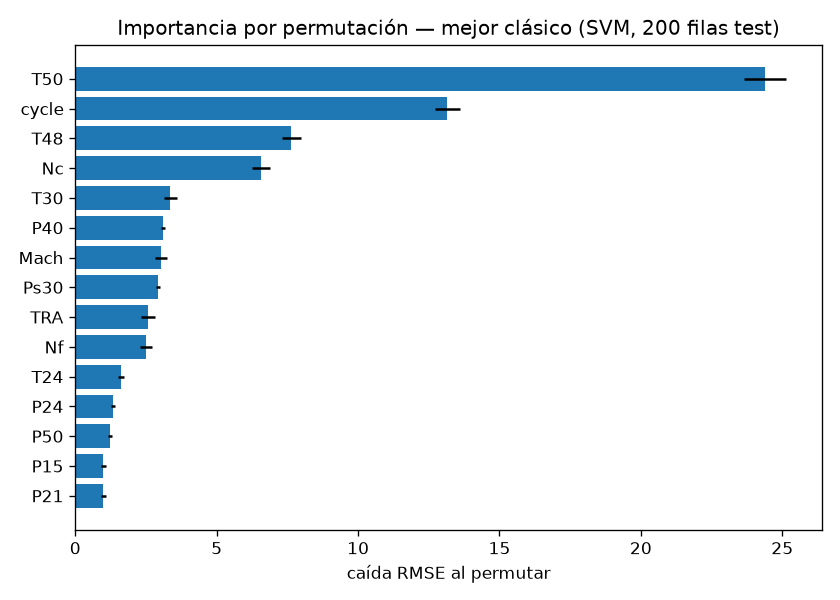

In [3]:
imp = pd.read_csv('../resultados/importancia_permutacion.csv')
print(imp.head(10).to_string(index=False))
print()
print('Lectura negocio: T50/cycle/T48 mandan; T30 (la sonda con dropout) pesa 5º: el ffill la sostiene.')
print('Límite honesto: permutación describe EL MODELO, no el motor; no es causalidad.')
from IPython.display import Image
Image('../resultados/importancia_permutacion.png')

## Cierre

- MLP mejor (E1) < mejor clásico (SVM 9.06): la capacidad ayuda hasta cierto punto.
- Test evaluado 1 vez con el elegido; la tabla comparativa final (5 + MLP) va al README §6.
- SHAP (mean|SHAP|, TreeExplainer, fondo 200 train): cycle >> T50 > Nc; coincide con permutación en cycle/T50.

## SHAP — qué variables pesan más (XGB, TreeExplainer exacto, 200 filas test)

Doble lectura: permutación (sobre el SVM elegido) + SHAP (sobre XGB). Si los dos métodos señalan lo mismo, la conclusión es robusta al método.

feature  mean_abs_shap
  cycle      34.092712
    T50       6.056539
     Nc       2.094185
     Wf       1.421452
   Mach       0.680943
    P40       0.605862
    T48       0.558896
     T2       0.454443
    P24       0.430943
     Nf       0.395379

QUÉ VEO: cycle concentra la atribución (desgaste acumulado); T50/Nc/Wf refinan.
CONCLUSIÓN: coincide con permutación en cycle/T50 — dos métodos independientes, misma historia. La fase_vuelo pesa poco: el régimen ya viene en alt/Mach.


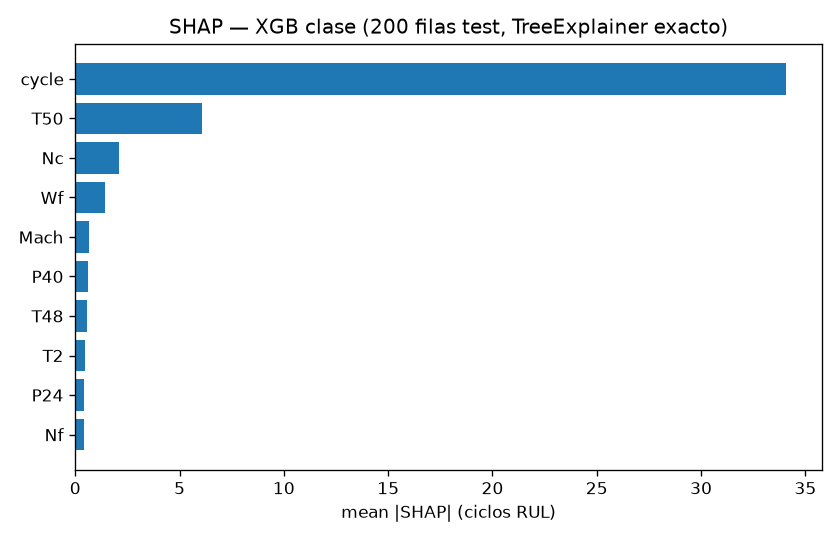

In [4]:
import pandas as pd
from IPython.display import Image

sh = pd.read_csv('../resultados/shap_importancia.csv')
print(sh.to_string(index=False))
print()
print('QUÉ VEO: cycle concentra la atribución (desgaste acumulado); T50/Nc/Wf refinan.')
print('CONCLUSIÓN: coincide con permutación en cycle/T50 — dos métodos independientes, '
      'misma historia. La fase_vuelo pesa poco: el régimen ya viene en alt/Mach.')
Image('../resultados/shap_importancia.png')
